# 01 — CNN Trained From Scratch

**Project:** Bangladeshi Freshwater Fish Image Classification Using CNN and Transfer Learning
**Dataset:** BFF-15 (15 classes)
**Owner:** Vivek Singh

## What this notebook does

1. Loads the frozen train/val/test splits from `data/splits/`.
2. Uses the shared pipeline in `data_utils.py` (no re-splitting, no re-augmentation).
3. Builds a CNN **from scratch**.
4. Trains with `ModelCheckpoint`, `CSVLogger`, `EarlyStopping`, `ReduceLROnPlateau`.
5. Saves all artifacts into `custom_cnn/`:
   - `custom_cnn/logs/training_log.csv`
   - `custom_cnn/best_model/best.keras`
   - `custom_cnn/plots/`
   - `custom_cnn/metrics/final_metrics.json` and `confusion_matrix.csv`

Notebook 03 will read these to compare against the transfer-learning model.

## Contract (must not change)

- Class mapping: `CLASS_NAMES` from `data_utils`.
- Splits: loaded from `data_utils.load_splits()`.
- Augmentation: `data_utils.get_train_ds()` only.
- Input normalization: `[0, 1]` (already applied inside `data_utils`).
- Image size: 224 × 224.
- Seed: 42.

The two model notebooks must use identical data so the comparison is valid.

In [5]:
import sys, json, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers

# PROJECT_ROOT comes from data_utils.__file__, not from the notebook's cwd, so
# artifacts land in the same place locally, in VS Code and in Colab.
sys.path.append(str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

from data_utils import (
    PROJECT_ROOT,
    get_train_ds, get_val_ds, get_test_ds, get_class_weights,
    CLASS_NAMES, CLASS_TO_IDX, IDX_TO_CLASS,
    IMG_SIZE, BATCH_SIZE, SEED,
)

# reproducibility
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Num classes:", len(CLASS_NAMES))
print("Image size:", IMG_SIZE)

TensorFlow: 2.21.0
Num classes: 15
Image size: (224, 224)


## Long-run safety

This runs on Google Colab, where a T4 session is reclaimed after roughly 12 hours and drops on ~90 minutes of idle. `ModelCheckpoint(save_best_only=True)` keeps only the winning weights and discards the epoch counter, the optimiser state and the learning-rate schedule, so a dropped session means starting over.

`ResumeFromCheckpoint` writes the live weights and the epoch count after every epoch to `best_model/last_state.kerasresumable`. Re-run the notebook after a drop and training continues from there; `initial_epoch=cb.epoch_ran` keeps the epoch numbering and the CSV log contiguous.


In [6]:
physical = tf.config.list_physical_devices("GPU")
if physical:
    try:                                   # don't grab all VRAM: colab notebooks share the T4
        for g in physical:
            tf.config.experimental.set_memory_growth(g, True)
    except Exception as exc:
        print("memory growth not set:", exc)
print("GPU:", physical[0].name if physical else "CPU only - move to Runtime > Change runtime type > T4")


GPU: /physical_device:GPU:0


In [7]:
CUSTOM_DIR   = PROJECT_ROOT / "custom_cnn"
LOGS_DIR     = CUSTOM_DIR / "logs"
PLOTS_DIR    = CUSTOM_DIR / "plots"
METRICS_DIR  = CUSTOM_DIR / "metrics"
CKPT_DIR     = CUSTOM_DIR / "best_model"

for d in [LOGS_DIR, PLOTS_DIR, METRICS_DIR, CKPT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

LOG_CSV      = LOGS_DIR / "training_log.csv"
CKPT_PATH    = CKPT_DIR / "best.keras"
METRICS_JSON = METRICS_DIR / "final_metrics.json"
CM_CSV       = METRICS_DIR / "confusion_matrix.csv"
RESUME_PATH  = CKPT_DIR / "last_state.kerasresumable"

print("Artifacts folder:", CUSTOM_DIR)

Artifacts folder: /content/custom_cnn


In [8]:
train_ds = get_train_ds()
val_ds   = get_val_ds()
test_ds  = get_test_ds()

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Val   batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test  batches:", tf.data.experimental.cardinality(test_ds).numpy())

Train batches: 115
Val   batches: 25
Test  batches: 25


## Build the CNN

**Vivek owns this cell.** A baseline architecture is provided so the notebook
is runnable. Replace or extend it if you want to experiment. Keep:

- input shape `(224, 224, 3)`,
- output layer `Dense(len(CLASS_NAMES), activation="softmax")`,
- a `Flatten` or `GlobalAveragePooling2D` before the classifier head.

Do **not** add pretrained weights here. This is the from-scratch model.

In [9]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return layers.MaxPooling2D()(x)

inputs = layers.Input(shape=(*IMG_SIZE, 3), name="image")      # already in [0, 1]
x = inputs
for f in (32, 64, 128, 256):
    x = conv_block(x, f)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASS_NAMES), activation="softmax", name="classifier")(x)

cnn = models.Model(inputs, outputs, name="custom_cnn")
cnn.compile(
    optimizer=optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
cnn.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             

 Total params: 1,209,967 (4.62 MB)

 Trainable params: 1,208,047 (4.61 MB)

 Non-trainable params: 1,920 (7.50 KB)

## Train
Class weights handle the imbalance (233 to 522 images per class). Best checkpoint is chosen on **validation** accuracy; the test set is touched only once, at the end.

In [10]:
import time
from eval_utils import ResumeFromCheckpoint

EPOCHS = 40
# Keep the weights in the notebook: this is a from-scratch CNN and Vivek owns the
# training recipe. They are recomputed from data/splits/train.csv, which changed
# after content de-duplication, so a hard-coded copy would be wrong.
class_weights = get_class_weights()
print("class weights:", {CLASS_NAMES[k]: round(v, 3) for k, v in class_weights.items()})

resume_cb = ResumeFromCheckpoint(RESUME_PATH)
cbs = [
    callbacks.ModelCheckpoint(str(CKPT_PATH), monitor="val_accuracy", mode="max", save_best_only=True, verbose=1),
    resume_cb,                                   # survives a dropped Colab session
    callbacks.CSVLogger(str(LOG_CSV), append=resume_cb.resumed),
    callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=10, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1),
]

t0 = time.time()
history = cnn.fit(train_ds, validation_data=val_ds,
                  initial_epoch=resume_cb.epoch_ran, epochs=EPOCHS,
                  class_weight=class_weights, callbacks=cbs)
train_seconds = time.time() - t0
epochs_ran = len(history.epoch) + resume_cb.epoch_ran
# captured before load_model(): after reloading, Keras reports every layer trainable again
trainable_params = int(sum(int(np.prod(w.shape)) for w in cnn.trainable_weights))

print(f"Trained {epochs_ran} epochs in {train_seconds/60:.1f} min")

class weights: {'GRASS CARP': 0.903, 'ILISH': 1.495, 'KATLA': 0.826, 'KOI': 0.87, 'MAGUR': 1.231, 'MIRROR CARP': 1.425, 'MRIGAL': 1.583, 'PABDA': 1.161, 'PANGAS': 0.683, 'PUTI': 0.923, 'RUI': 0.702, 'SHOL': 1.177, 'SILVER CARP': 1.593, 'TELAPIA': 0.909, 'TENGRA': 0.764}
ResumeFromCheckpoint: restored last_state.weights.h5 at epoch 2
Epoch 1/40


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 58 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 586ms/step - accuracy: 0.4044 - loss: 1.6634
Epoch 1: val_accuracy improved from None to 0.04470, saving model to /content/custom_cnn/best_model/best.keras

Epoch 1: finished saving model to /content/custom_cnn/best_model/best.keras
115/115 ━━━━━━━━━━━━━━━━━━━━ 102s 638ms/step - accuracy: 0.4305 - loss: 1.5945 - val_accuracy: 0.0447 - val_loss: 22.5569 - learning_rate: 0.0010
Epoch 2/40
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 436ms/step - accuracy: 0.4479 - loss: 1.5236
Epoch 2: val_accuracy improved from 0.04470 to 0.09195, saving model to /content/custom_cnn/best_model/best.keras

Epoch 2: finished saving model to /content/custom_cnn/best_model/best.keras
115/115 ━━━━━━━━━━━━━━━━━━━━ 52s 449ms/step - accuracy: 0.4650 - loss: 1.4654 - val_accuracy: 0.0920 - val_loss: 11.0931 - learning_rate: 0.0010
Epoch 3/40
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 441ms/step - accuracy: 0.4935 - loss: 1.3730
Epoch 3: val_accuracy did not improve from 0.09195
115/115 ━━━━━━━━━━━━━━━━━━

## Evaluate on the test set
Saves `final_metrics.json`, `confusion_matrix.csv`, and the plots notebook 03 reads.

In [11]:
# Evaluation lives in eval_utils.py and is shared with 02_transfer_learning, so the
# two folders cannot drift into different schemas - 03_comparison reads both.
# Same artifact paths and same final_metrics.json keys as before.
from eval_utils import evaluate_and_save, plot_curves


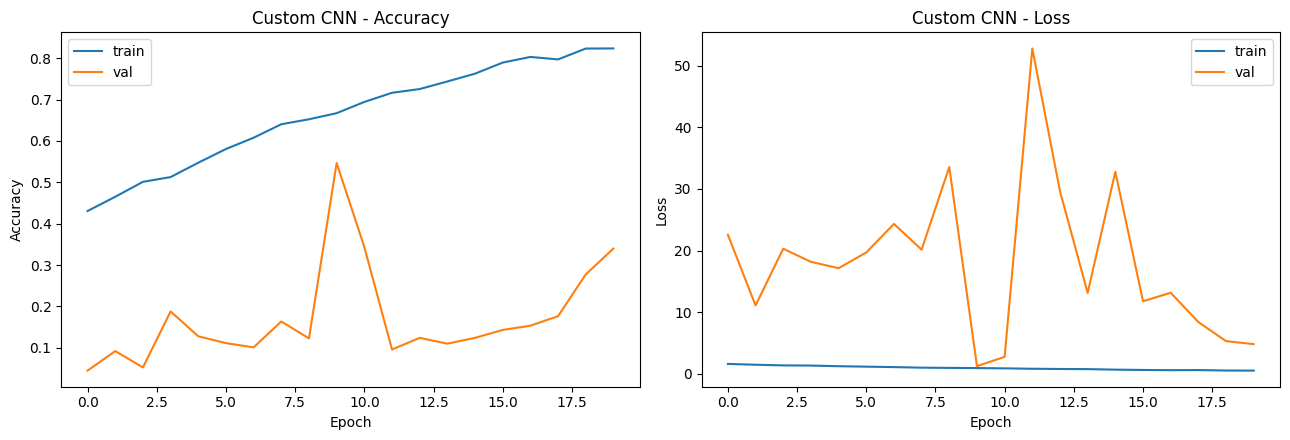

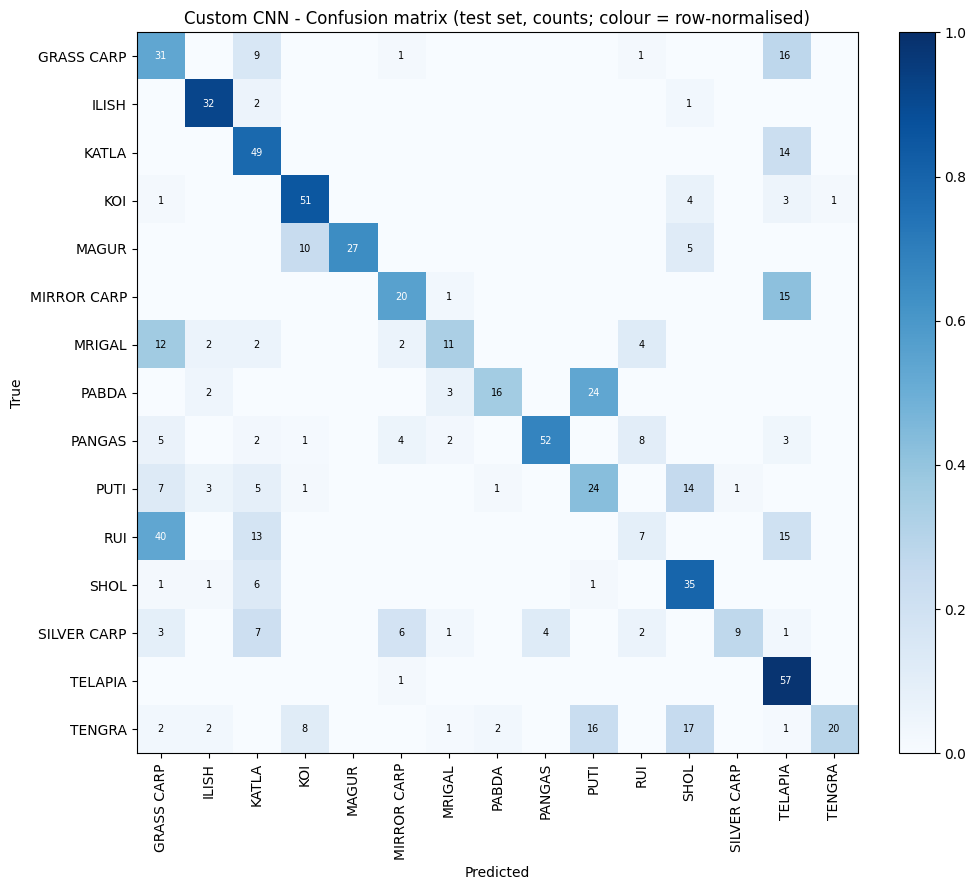

Test accuracy : 0.5625
Top-5 accuracy: 0.9605
Macro  P/R/F1 : 0.6463 / 0.5668 / 0.5525
Weight P/R/F1 : 0.6355 / 0.5625 / 0.5444
             precision  recall     f1  support
GRASS CARP       0.304   0.534  0.388     58.0
ILISH            0.762   0.914  0.831     35.0
KATLA            0.516   0.778  0.620     63.0
KOI              0.718   0.850  0.779     60.0
MAGUR            1.000   0.643  0.783     42.0
MIRROR CARP      0.588   0.556  0.571     36.0
MRIGAL           0.579   0.333  0.423     33.0
PABDA            0.842   0.356  0.500     45.0
PANGAS           0.929   0.675  0.782     77.0
PUTI             0.369   0.429  0.397     56.0
RUI              0.318   0.093  0.144     75.0
SHOL             0.461   0.795  0.583     44.0
SILVER CARP      0.900   0.273  0.419     33.0
TELAPIA          0.456   0.983  0.623     58.0
TENGRA           0.952   0.290  0.444     69.0


In [12]:
plot_curves(LOG_CSV, "Custom CNN", PLOTS_DIR / "training_curves.png")

best = tf.keras.models.load_model(CKPT_PATH)   # evaluate the best checkpoint, not the last epoch
cnn_metrics = evaluate_and_save(
    best, test_ds, "Custom CNN", epochs_ran, train_seconds,
    METRICS_JSON, CM_CSV, PLOTS_DIR / "confusion_matrix.png",
    trainable_params=trainable_params,
)
